# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/begs44/flyrank-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**How the queue is built:**
- **Priority score:** Logistic Regression, chosen because it tied with Gradient Boosting in Week 5 and is the simpler model. Every page is scored by a model that never saw its client (grouped 5-fold, out-of-fold scores). Measured P@50 = 0.80, against 0.75 for my rule and a 0.54 base rate.
- **Archetype → reason code → action:** transparent rules built on the signals that held up in Weeks 4 and 6.

| Archetype | Reason code | Action | n | Measured decline |
|---|---|---|---|---|
| A0 tiny / noisy page (< 100 impr.) | too_little_data | no_action_monitor | 7,994 | 0.39 |
| A1 zero clicks on big visibility (≥ 5k impr.) | possible_tracking_issue | check_tracking_before_editing | 32 | 0.75 |
| A2 visible but under-clicked | low_ctr_for_position | rewrite_title_and_meta | 5,799 | 0.67 |
| A3 striking distance (pos 11–20) | near_page_one | refresh_content_and_internal_links | 2,300 | 0.57 |
| A4 healthy page-one asset | protect_page_one | light_fact_check_refresh | 3,892 | 0.51 |
| A5 deep or no ranking | low_visibility | deprioritize_or_consolidate | 6,915 | 0.55 |
| A6 small but ranking (100–499 impr.) | small_but_ranking | batch_review_later | 3,068 | 0.70 |

- **This week's batch:** the 50 highest-priority pages from A1–A4, with **at most 10 per client** so one site cannot take over the list. The batch has a measured decline rate of 0.78 and ended up as 37 title/meta rewrites and 13 tracking checks.

**The decay / refresh insight:**
- **Low CTR for a page's position is the clearest warning signal** (CONFIRMED in Weeks 4 and 6).
- **Younger pages (90–269 days) decline more than older ones.** This is the opposite of the common "old pages decay" belief.
- **Being stale is not a reliable trigger on its own.** The 180+ day flag had too few visible pages to confirm it.

So in this data, "refresh by age" is weaker guidance than "fix under-clicked visible pages first".

**Weak points:**
- A1 has only 32 pages, so its rate is uncertain.
- A6 declines at 0.70, but it is left out of this week's batch because those pages carry little traffic (see cost/value).

In [3]:
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

SEED = 42
url = "https://raw.githubusercontent.com/begs44/flyrank-ml/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)
df["target_decay"] = (df["trend_direction"] == "down").astype(int)   # used only to MEASURE, never as an input
base = df["target_decay"].mean()

# ---- Week-5 features (unchanged) ----
df["avg_position"] = df["avg_position"].replace(0, np.nan)
df["has_word_count"] = df["word_count"].notna().astype(int)
df["has_keyword_data"] = df["search_volume"].notna().astype(int)
for c in ["impressions_90d", "clicks_90d", "sessions_90d", "ai_sessions_90d"]:
    df[f"log_{c}"] = np.log1p(df[c])
NUMERIC = ["search_volume", "competition", "cpc", "word_count",
           "log_impressions_90d", "log_clicks_90d", "log_sessions_90d", "log_ai_sessions_90d",
           "days_with_impressions", "days_with_sessions", "content_age_days", "days_since_last_update",
           "ctr", "avg_position", "engagement_rate", "scroll_rate", "ai_traffic_pct",
           "has_word_count", "has_keyword_data"]
CATEGORICAL = ["content_type", "main_intent", "competition_level"]
df[CATEGORICAL] = df[CATEGORICAL].fillna("unknown")
X, y = df[NUMERIC + CATEGORICAL], df["target_decay"]

# ---- Priority score: Logistic Regression (tied with Gradient Boosting in W5 -> simpler one wins).
# Every page is scored by a model that never saw its client (grouped out-of-fold).
def make_lr():
    pre = make_column_transformer((make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
                                  (OneHotEncoder(handle_unknown="ignore"), CATEGORICAL))
    return make_pipeline(pre, LogisticRegression(max_iter=2000, C=0.5))

df["priority_score"] = np.nan
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=df["client_id"]):
    df.loc[df.index[te], "priority_score"] = make_lr().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]

# ---- Archetype -> reason code -> action (transparent rules, checked in Weeks 4 and 6) ----
bands = [0, 3, 5, 10, 15, 20]
visible = (df["impressions_90d"] >= 500) & (df["avg_position"] <= 20)
exp_ctr = df[visible].groupby(pd.cut(df.loc[visible, "avg_position"], bands), observed=True)["ctr"].median()
df["ctr_vs_expected"] = df["ctr"] / pd.cut(df["avg_position"], bands).map(exp_ctr).astype(float)

conditions = [
    df["impressions_90d"] < 100,
    visible & (df["clicks_90d"] == 0) & (df["impressions_90d"] >= 5000),
    visible & (df["ctr_vs_expected"] < 1),
    visible & (df["avg_position"] > 10),
    visible,
    df["avg_position"].isna() | (df["avg_position"] > 20),
]
archetypes = ["A0 tiny / noisy page", "A1 zero clicks on big visibility", "A2 visible but under-clicked",
              "A3 striking distance (11-20)", "A4 healthy page-one asset", "A5 deep or no ranking"]
reason = ["too_little_data", "possible_tracking_issue", "low_ctr_for_position",
          "near_page_one", "protect_page_one", "low_visibility"]
action = ["no_action_monitor", "check_tracking_before_editing", "rewrite_title_and_meta",
          "refresh_content_and_internal_links", "light_fact_check_refresh", "deprioritize_or_consolidate"]
df["archetype"] = np.select(conditions, archetypes, default="A6 small but ranking (100-499 impr.)")
df["reason_code"] = np.select(conditions, reason, default="small_but_ranking")
df["action"] = np.select(conditions, action, default="batch_review_later")

arch = df.groupby("archetype").agg(pages=("target_decay", "size"), reason_code=("reason_code", "first"),
                                   action=("action", "first"), mean_priority=("priority_score", "mean"),
                                   measured_decline_rate=("target_decay", "mean")).round(3)
print(f"Archetype -> action map (base rate {base:.3f}; decline rate is measured hindsight, not an input):\n")
print(arch.to_string(), "\n")

# ---- The weekly queue: ranked by priority, actionable archetypes only, max 10 pages per client ----
ACTIONABLE = ["A1 zero clicks on big visibility", "A2 visible but under-clicked",
              "A3 striking distance (11-20)", "A4 healthy page-one asset"]
CAPACITY, CLIENT_CAP = 50, 10
queue = df.sort_values("priority_score", ascending=False).copy()          # FULL ranked queue (all pages)
queue["rank"] = np.arange(1, len(queue) + 1)
queue["actionable"] = queue["archetype"].isin(ACTIONABLE)
queue["client_rank"] = queue[queue["actionable"]].groupby("client_id").cumcount() + 1
eligible = queue["actionable"] & (queue["client_rank"] <= CLIENT_CAP)
queue["this_week_batch"] = False
queue.loc[queue[eligible].index[:CAPACITY], "this_week_batch"] = True
queue["batch_rank"] = queue["this_week_batch"].cumsum().where(queue["this_week_batch"]).astype("Int64")
top = queue[queue["this_week_batch"]]
print(f"Queue: {len(queue):,} pages ranked, {queue['actionable'].sum():,} actionable | this week's batch = top {CAPACITY} actionable (max {CLIENT_CAP} per client)")
print(f"Measured decline rate in the batch: {top['target_decay'].mean():.2f} vs base rate {base:.2f}\n")
print(top.groupby(["archetype", "action"]).size().rename("pages in batch").to_string(), "\n")
print(top.head(10)[["batch_rank", "archetype", "reason_code", "action", "priority_score", "impressions_90d",
                    "clicks_90d", "avg_position", "ctr", "content_age_days"]].round(3).to_string(index=False))

Archetype -> action map (base rate 0.542; decline rate is measured hindsight, not an input):

                                      pages              reason_code                              action  mean_priority  measured_decline_rate
archetype                                                                                                                                     
A0 tiny / noisy page                   7994          too_little_data                   no_action_monitor          0.418                  0.389
A1 zero clicks on big visibility         32  possible_tracking_issue       check_tracking_before_editing          0.879                  0.750
A2 visible but under-clicked           5799     low_ctr_for_position              rewrite_title_and_meta          0.727                  0.665
A3 striking distance (11-20)           2300            near_page_one  refresh_content_and_internal_links          0.554                  0.572
A4 healthy page-one asset              3892     

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use:** a weekly triage list for a content/SEO editor. It answers *"which 50 pages should I look at first, and what should I check?"* It is **decision support**: a human reads every page and decides. It is not a publishing system and not a forecast.

**Cost / value (assumptions stated):**
- **Time:** at an assumed 0.5 h per tracking check, 0.75 h per title/meta rewrite, 3 h per content refresh and 1 h per fact-check, the batch costs about **34 editor-hours** (~41 min per page).
- **Hit rate:** in hindsight, about **39 of the 50** pages were declining. A random pick of 50 actionable pages gives about 30 (5th–95th percentile 24–36), so the queue saves roughly 9 wasted reviews per batch.
- **Value:** captured click-equivalent value (clicks × CPC, the paper's safe proxy) is only **~$12** for the batch, because these pages get almost no clicks. The case for acting is the **~700k impressions of visibility at stake**, not revenue. That is also why tiny pages (A0, A6) are left out: little to win, noisy labels.

**Limits: where it stops being valid:**
- **One snapshot:** 30k pages from 32 clients, content aged 90–564 days, three content types. Outside this range it has not been validated.
- **Overlapping windows:** the signals are 90-day totals that overlap the label's 30-day window (Week 6). The model **recognizes decline in progress better than it forecasts it**.
- **The label is noisy for small pages:** one impression can flip it.
- **Nothing here shows that a refresh causes recovery.** That would need a before/after or controlled test.

In [4]:
# ---- Cost / value thinking for this week's batch (assumptions are stated, not measured) ----
HOURS = {"check_tracking_before_editing": 0.5, "rewrite_title_and_meta": 0.75,
         "refresh_content_and_internal_links": 3.0, "light_fact_check_refresh": 1.0}   # editor-hour ASSUMPTIONS
top = top.assign(est_hours=top["action"].map(HOURS),
                 click_value_90d=(top["clicks_90d"] * top["cpc"].fillna(0)).round(2))  # paper's safe proxy: clicks x CPC

rng = np.random.default_rng(SEED)
pool = queue[queue["actionable"]]
random_rates = [pool.sample(CAPACITY, random_state=int(s))["target_decay"].mean() for s in rng.integers(0, 10_000, 200)]

print(f"Batch of {CAPACITY}: estimated editor time {top['est_hours'].sum():.1f} h "
      f"({top['est_hours'].sum() / CAPACITY * 60:.0f} min per page on average)")
print(f"Measured decline rate: batch {top['target_decay'].mean():.2f} | random 50 actionable pages "
      f"{np.mean(random_rates):.2f} (5th-95th pct {np.percentile(random_rates, 5):.2f}-{np.percentile(random_rates, 95):.2f}) | base {base:.2f}")
print(f"=> about {top['target_decay'].sum()} of 50 reviewed pages were declining, vs ~{np.mean(random_rates) * CAPACITY:.0f} for a random pick")
print(f"Captured click-equivalent value of the batch (clicks x CPC, 90d): ${top['click_value_90d'].sum():,.2f} "
      f"— small, because these pages get few clicks; the case is about visibility at risk, not revenue.")
print(f"Impressions at stake in the batch (90d): {top['impressions_90d'].sum():,}")

# ---- Where the playbook is valid: coverage of the training data ----
print(f"\nValid range (this snapshot): {df['client_id'].nunique()} clients, {len(df):,} pages, "
      f"content age {df['content_age_days'].min()}-{df['content_age_days'].max()} days, "
      f"content types {sorted(df['content_type'].unique())}")

Batch of 50: estimated editor time 34.2 h (41 min per page on average)
Measured decline rate: batch 0.78 | random 50 actionable pages 0.60 (5th-95th pct 0.48-0.72) | base 0.54
=> about 39 of 50 reviewed pages were declining, vs ~30 for a random pick
Captured click-equivalent value of the batch (clicks x CPC, 90d): $11.94 — small, because these pages get few clicks; the case is about visibility at risk, not revenue.
Impressions at stake in the batch (90d): 699,698

Valid range (this snapshot): 32 clients, 30,000 pages, content age 90-564 days, content types ['comparison article', 'feedly article', 'keyword article']


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Before acting on any page, the editor checks:**
1. **Open the page and its search results.** Does the low CTR have an obvious outside cause, such as ads, an AI overview or a featured snippet? If yes, a title rewrite will not help. Skip it.
2. **Zero clicks (38 of 50 pages this week):** confirm in Search Console that clicks are not being credited to another URL (canonical, redirect, tracking) **before** editing anything.
3. **Updated in the last 14 days (10 pages):** wait. The last change may not be re-indexed yet.
4. **Position 1–3 with near-zero CTR (6 pages):** suspicious. Check which queries the average position comes from.
5. **Transactional intent (5 pages):** check whether shopping ads take the clicks.
6. Write down the decision and the reason, so next month's batch can be checked against it.

Only 6 of the 50 pages carry no extra flag. **Human review is the main step here, not an optional one.**

**NO-GO list: never automated:**
- Publishing any change without an editor reading the page.
- Deleting, noindexing or redirecting a page because of its score.
- Rewriting A0 tiny pages (the label is noise below 100 impressions).
- Editing A1 pages before tracking/canonical is checked.
- Re-editing a page updated in the last 14 days.
- Using the score to judge writers, clients or AI providers.
- Applying the queue to new clients or content types outside the valid range without re-validating.

In [5]:
# ---- Review flags: each one means "a human must look before acting" ----
flags = pd.DataFrame(index=top.index)
flags["zero_clicks_check_tracking"] = top["clicks_90d"] == 0
flags["updated_last_14d"]        = top["days_since_last_update"] <= 14
flags["position_top3_tiny_ctr"]  = (top["avg_position"] <= 3) & (top["ctr"] < 0.05)
flags["transactional_intent"]    = top["main_intent"].eq("transactional")
flags["missing_word_count"]      = top["word_count"].isna()
top = top.assign(review_flags=flags.apply(lambda r: "|".join(r.index[r]) or "standard_review", axis=1))
queue.loc[top.index, "review_flags"] = top["review_flags"]

print("Review flags in this week's batch (a page can carry several):")
print(flags.sum().to_string())
print(f"\nPages with no extra flag (standard review only): {(top['review_flags'] == 'standard_review').sum()} of {CAPACITY}")
print(f"Largest single-client share of the batch: {top['client_id'].value_counts().iloc[0]} pages (cap {CLIENT_CAP})")

NO_GO = ["publishing any change without an editor reading the page",
         "deleting, noindexing or redirecting a page based on the score",
         "rewriting A0 tiny pages (label is noise at <100 impressions)",
         "editing A1 pages before tracking/canonical is checked",
         "re-editing a page updated in the last 14 days",
         "using the score to judge writers, clients or AI providers",
         "applying the queue to new clients/content types outside the valid range without re-validation"]
print("\nNO-GO list (never automated):")
for i, item in enumerate(NO_GO, 1):
    print(f"  {i}. {item}")

Review flags in this week's batch (a page can carry several):
zero_clicks_check_tracking    38
updated_last_14d              10
position_top3_tiny_ctr         6
transactional_intent           5
missing_word_count             8

Pages with no extra flag (standard review only): 6 of 50
Largest single-client share of the batch: 10 pages (cap 10)

NO-GO list (never automated):
  1. publishing any change without an editor reading the page
  2. deleting, noindexing or redirecting a page based on the score
  3. rewriting A0 tiny pages (label is noise at <100 impressions)
  4. editing A1 pages before tracking/canonical is checked
  5. re-editing a page updated in the last 14 days
  6. using the score to judge writers, clients or AI providers
  7. applying the queue to new clients/content types outside the valid range without re-validation


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**What would tell me the recommendations went stale?** The code saves today's reference values, then checks them every month:

- **Hit rate drops:** last month's batch, checked in hindsight, has a decline rate below the rule baseline (0.75). Then the model is no better than the simple rule, so fall back to the rule and retrain.
- **The label shifts:** the share of declining pages moves more than 10 points from 0.54. The meaning of "decline" has changed (seasonality, a core update).
- **The search results change:** the median CTR of visible pages moves more than 30% from 0.21%. Probably more AI overviews or ads, so the "low CTR for position" benchmark needs recalculating.
- **The portfolio changes:** the share of tiny pages moves more than 10 points from 0.27, or a new client or content type joins.
- **Schedule:** re-validate monthly with a grouped split. Retrain at least quarterly. Re-check right after any Google core update.

Light and practical: this is a spreadsheet check, not a production monitoring system.

In [6]:
# ---- Reference values today: the numbers to compare against every month ----
reference = {
    "base_rate": round(float(base), 3),
    "batch_decline_rate": round(float(top["target_decay"].mean()), 3),
    "grouped_cv_p_at_50_lr": 0.800,             # from w05 / w06 (client-grouped 5-fold)
    "rule_baseline_p_at_50": 0.752,
    "share_visible_under_clicked": round(float((df["archetype"] == "A2 visible but under-clicked").mean()), 3),
    "median_ctr_visible": round(float(df.loc[visible, "ctr"].median()), 3),
    "median_position_visible": round(float(df.loc[visible, "avg_position"].median()), 2),
    "share_tiny_pages": round(float((df["impressions_90d"] < 100).mean()), 3),
}
TRIGGERS = {
    "batch_decline_rate": ("hindsight hit-rate of last month's batch falls below rule baseline", 0.752),
    "base_rate":          ("share of declining pages moves more than 10 points", (round(reference["base_rate"] - 0.10, 3), round(reference["base_rate"] + 0.10, 3))),
    "median_ctr_visible": ("median CTR of visible pages shifts more than 30% (SERP/AI-overview change)",
                           (round(reference["median_ctr_visible"] * 0.7, 3), round(reference["median_ctr_visible"] * 1.3, 3))),
    "share_tiny_pages":   ("share of <100-impression pages moves more than 10 points (portfolio mix change)",
                           (round(reference["share_tiny_pages"] - 0.10, 3), round(reference["share_tiny_pages"] + 0.10, 3))),
}
print("Reference values (today):")
for k, v in reference.items():
    print(f"  {k:<30} {v}")
print("\nRetrain / re-check triggers:")
for k, (why, limit) in TRIGGERS.items():
    print(f"  - {why}  [watch: {k}, limit: {limit}]")
print("  - a new client or content type joins (outside the valid range)")
print("  - Google core update or a clear SERP layout change")
print("  - scheduled: re-validate monthly, retrain at least quarterly")

Reference values (today):
  base_rate                      0.542
  batch_decline_rate             0.78
  grouped_cv_p_at_50_lr          0.8
  rule_baseline_p_at_50          0.752
  share_visible_under_clicked    0.193
  median_ctr_visible             0.21
  median_position_visible        8.2
  share_tiny_pages               0.266

Retrain / re-check triggers:
  - hindsight hit-rate of last month's batch falls below rule baseline  [watch: batch_decline_rate, limit: 0.752]
  - share of declining pages moves more than 10 points  [watch: base_rate, limit: (0.442, 0.642)]
  - median CTR of visible pages shifts more than 30% (SERP/AI-overview change)  [watch: median_ctr_visible, limit: (0.147, 0.273)]
  - share of <100-impression pages moves more than 10 points (portfolio mix change)  [watch: share_tiny_pages, limit: (0.166, 0.366)]
  - a new client or content type joins (outside the valid range)
  - Google core update or a clear SERP layout change
  - scheduled: re-validate monthly, retrain

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

**Files this notebook writes (the paper builds on these):**
- **`work/outputs/w07_action_queue.csv`:** all 30,000 pages ranked, with `rank`, `this_week_batch`, `batch_rank`, `priority_score`, `archetype`, `reason_code`, `action` and `review_flags`. It is regenerated on every run and stays out of git by design (the CI leak guard blocks data files).
- **`work/outputs/w07_playbook_metrics.json`:** the receipt. Model settings, capacity, archetype decline rates and reference values. The paper's numbers trace back to this file. Committed.
- **`work/figures/w07_playbook_insights.png`:** decline rate by archetype, and by content age. Committed, to reuse in the paper.

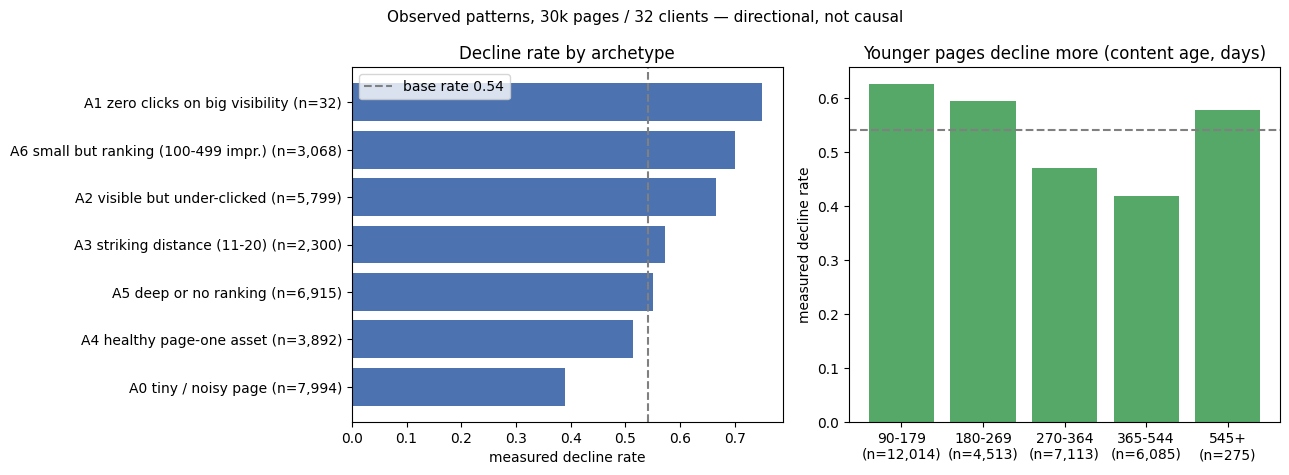

wrote work/outputs/w07_action_queue.csv  (5,444,890 bytes)
wrote work/outputs/w07_playbook_metrics.json  (1,373 bytes)
wrote work/figures/w07_playbook_insights.png  (125,371 bytes)


In [7]:
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# ---- 1. Full ranked queue (regenerated on every run; stays out of git by design) ----
export_cols = ["rank", "this_week_batch", "batch_rank", "content_id", "client_id", "priority_score",
               "archetype", "reason_code", "action", "review_flags", "impressions_90d", "clicks_90d",
               "avg_position", "ctr", "ctr_vs_expected", "content_age_days", "days_since_last_update",
               "content_type", "main_intent"]
queue["review_flags"] = queue["review_flags"].fillna("")
queue[export_cols].round(4).to_csv("work/outputs/w07_action_queue.csv", index=False)

# ---- 2. Figure for the paper: archetype decline rates + age pattern ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
a = arch.sort_values("measured_decline_rate")
axes[0].barh([f"{i} (n={n:,})" for i, n in zip(a.index, a["pages"])], a["measured_decline_rate"], color="#4C72B0")
axes[0].axvline(base, color="grey", ls="--", label=f"base rate {base:.2f}")
axes[0].set_xlabel("measured decline rate"); axes[0].set_title("Decline rate by archetype"); axes[0].legend()
age = df.groupby(pd.cut(df["content_age_days"], [90, 180, 270, 365, 545, 10_000], right=False,
                        labels=["90-179", "180-269", "270-364", "365-544", "545+"]), observed=True)["target_decay"].agg(["mean", "size"])
axes[1].bar([f"{i}\n(n={n:,})" for i, n in zip(age.index, age["size"])], age["mean"], color="#55A868")
axes[1].axhline(base, color="grey", ls="--")
axes[1].set_ylabel("measured decline rate"); axes[1].set_title("Younger pages decline more (content age, days)")
plt.suptitle("Observed patterns, 30k pages / 32 clients — directional, not causal", fontsize=11)
plt.tight_layout()
plt.savefig("work/figures/w07_playbook_insights.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- 3. Metrics receipt (small JSON — worth committing) ----
receipt = {"notebook": "w07_action_playbook", "model": "LogisticRegression C=0.5, grouped 5-fold OOF by client",
           "capacity": CAPACITY, "client_cap": CLIENT_CAP, "rows": int(len(queue)),
           "actionable": int(queue["actionable"].sum()), "batch_hours_estimate": float(top["est_hours"].sum()),
           "archetypes": arch[["pages", "measured_decline_rate"]].reset_index().to_dict(orient="records"),
           "reference": reference}
with open("work/outputs/w07_playbook_metrics.json", "w") as f:
    json.dump(receipt, f, indent=2)

for p in ["work/outputs/w07_action_queue.csv", "work/outputs/w07_playbook_metrics.json", "work/figures/w07_playbook_insights.png"]:
    print(f"wrote {p}  ({os.path.getsize(p):,} bytes)")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.